# Labelbox Annotation Summary — STEPS-Paper-Annotation

Reads the Labelbox NDJSON export directly (no Labelbox API calls needed for
this notebook — it only summarizes labels already exported) and reproduces
the annotation-progress charts: pages with/without graphics, object type
counts, and figure subtype counts.

**Fixed in this version:**
- Export path now points at `Pre-Pages-2Annotate/`, where the export lives
  alongside the manifest and page images (previously pointed two directories
  up to a file that no longer existed there).
- Object-type and figure-subtype counts now look at *every* annotated object
  per page, not just the first one. The previous version built a wide
  DataFrame from Python lists (`pd.DataFrame(objects_rows)`) and only ever
  read column `0` — silently dropping every second, third, ... box on any
  page with more than one annotation. **21 of the 78 annotated pages have
  more than one object**, so the old Figure/Table and subtype charts were
  undercounting (78 boxes counted vs. 105 actually present).
- Replaced the chained `pd.DataFrame(df[col].tolist())` flattening (fragile —
  depends on dict key order and silently breaks if a project ever has more
  than one label or ontology) with explicit, defensive JSON traversal.


In [1]:
import json
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt

EXPORT_PATH = Path("..") / ".." / "Pre-Pages-2Annotate" / "Export  project - STEPS-Paper-Annotation - 6_11_2026.ndjson"
MANIFEST_PATH = Path("..") / ".." / "Pre-Pages-2Annotate" / "manifest.csv"

assert EXPORT_PATH.exists(), f"Export not found at {EXPORT_PATH.resolve()}"


## Load and flatten the export

Each line of the NDJSON is one Labelbox data row (one page image). `select_label` picks which label to use when a data row has more than one (Labelbox consensus workflows can attach several independent labels per row) — this project's `consensus_expected_label_count` is 3, so we default to the first label, matching a single-source-of-truth read.

In [2]:
def flatten_classifications(classifications):
    """Turn Labelbox's nested classification structure into ['Name:answer', ...]."""
    out = []
    for c in classifications or []:
        cname = c.get("name", "")
        for ans in c.get("checklist_answers", []):
            out.append(f"{cname}:{ans.get('value', '')}")
            out.extend(flatten_classifications(ans.get("classifications", [])))
        if isinstance(c.get("answer"), dict):
            ans = c["answer"]
            out.append(f"{cname}:{ans.get('value', '')}")
            out.extend(flatten_classifications(ans.get("classifications", [])))
    return out


def select_label(labels, mode="first"):
    if not labels:
        return None
    return labels[0] if mode == "first" else labels  # mode="all" handled by caller if ever needed


pages = []          # one row per data_row (page)
objects_flat = []   # one row per annotated object (box)

with open(EXPORT_PATH) as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        row = json.loads(line)
        external_id = row.get("data_row", {}).get("external_id", "")

        page_objects, page_no_graphics_flag, label_found = [], False, False

        for project_id, project in row.get("projects", {}).items():
            label = select_label(project.get("labels", []), mode="first")
            if label is None:
                continue
            label_found = True
            ann = label.get("annotations", {})
            page_objects.extend(ann.get("objects", []))

            for c in ann.get("classifications", []):
                for ans in c.get("checklist_answers", []):
                    if ans.get("value") == "no_graphics":
                        page_no_graphics_flag = True

        pages.append({
            "image": external_id,
            "has_label": label_found,
            "n_objects": len(page_objects),
            "explicit_no_graphics": page_no_graphics_flag,
        })

        for obj in page_objects:
            objects_flat.append({
                "image": external_id,
                "class": obj.get("name", "unlabeled"),
                "subtypes": ";".join(flatten_classifications(obj.get("classifications", []))),
                "feature_id": obj.get("feature_id", ""),
            })

df_pages = pd.DataFrame(pages)
df_objects = pd.DataFrame(objects_flat)

print(f"Pages in export:   {len(df_pages)}")
print(f"Objects extracted: {len(df_objects)}")
df_pages.head()


Pages in export:   124
Objects extracted: 105


,image,has_label,n_objects,explicit_no_graphics
0,Additives-for-reducing-nitrogen-loss-during-co...,True,0,True
1,Additives-for-reducing-nitrogen-loss-during-co...,True,1,False
2,Additives-for-reducing-nitrogen-loss-during-co...,True,1,False
3,Additives-for-reducing-nitrogen-loss-during-co...,True,1,False
4,Additives-for-reducing-nitrogen-loss-during-co...,True,2,False


## Pages with graphics vs. no graphics

This matches the original notebook's definition exactly: a page counts as "no graphics" whenever it has zero annotated objects — whether the labeler explicitly checked **No Graphics**, or submitted an empty label without checking anything. The breakdown just below splits those two cases apart, since they mean different things for QA.

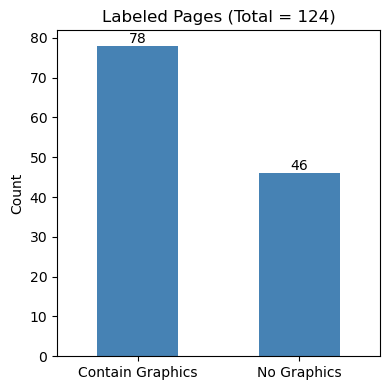

In [3]:
count_total = len(df_pages)
count_graphics = int((df_pages["n_objects"] > 0).sum())
count_no_graphics = count_total - count_graphics

counts_total = {"Contain Graphics": count_graphics, "No Graphics": count_no_graphics}

ax = pd.Series(counts_total).sort_values(ascending=False).plot(
    kind="bar", figsize=(4, 4), color="steelblue"
)
ax.bar_label(ax.containers[0])
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.title(f"Labeled Pages (Total = {count_total})")
plt.tight_layout()
plt.show()


In [4]:
# Diagnostic: within "No Graphics", how many were explicitly marked vs. left blank?
explicit_no_graphics = int(df_pages["explicit_no_graphics"].sum())
blank_submissions = count_no_graphics - explicit_no_graphics

print(f"No Graphics (explicitly checked):  {explicit_no_graphics}")
print(f"No Graphics (blank / unchecked):    {blank_submissions}")
if blank_submissions:
    print(
        f"\n{blank_submissions} page(s) were submitted with neither an object "
        f"nor the 'No Graphics' checkbox — worth a second look before treating "
        f"them as confirmed blank pages."
    )


No Graphics (explicitly checked):  7
No Graphics (blank / unchecked):    39

39 page(s) were submitted with neither an object nor the 'No Graphics' checkbox — worth a second look before treating them as confirmed blank pages.


## Object type counts (Figure / Table / ...)

Counted across **every** annotated object, not just the first one per page.

{'Figure': 62, 'Table': 43}


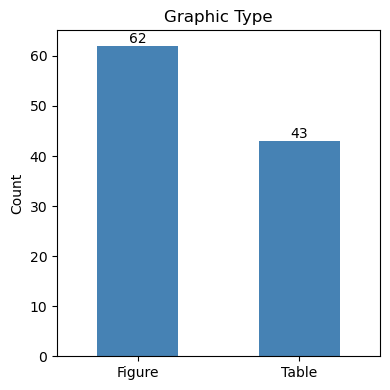

In [5]:
counts_graphics = df_objects["class"].value_counts().to_dict()
print(counts_graphics)

ax = pd.Series(counts_graphics).sort_values(ascending=False).plot(
    kind="bar", figsize=(4, 4), color="steelblue"
)
ax.bar_label(ax.containers[0])
plt.ylabel("Count")
plt.title("Graphic Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Figure subtype counts (Diagram / Plot)

A `Figure` can carry more than one subtype answer (a figure panel that's part diagram, part plot) — those are counted once per subtype rather than forced into a single label, since collapsing them would misrepresent mixed figures either way.

{'diagram': 23, 'plot': 44}


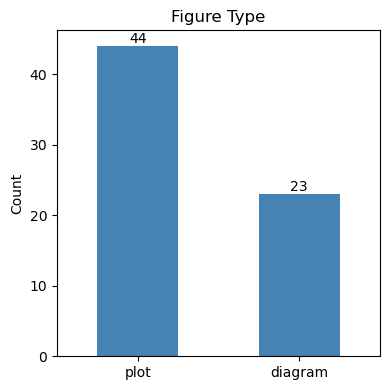

In [6]:
subtype_counter = Counter()
for subtypes in df_objects.loc[df_objects["class"] == "Figure", "subtypes"]:
    for tag in filter(None, subtypes.split(";")):
        # tag looks like "Type:plot" -> keep just the answer
        subtype_counter[tag.split(":", 1)[-1]] += 1

counts_figure = dict(subtype_counter)
print(counts_figure)

ax = pd.Series(counts_figure).sort_values(ascending=False).plot(
    kind="bar", figsize=(4, 4), color="steelblue"
)
ax.bar_label(ax.containers[0])
plt.ylabel("Count")
plt.title("Figure Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Annotation progress by topic

Cross-references the flat object list against `manifest.csv` (topic → paper mapping) to show how much of each topic folder has been labeled so far.

In [7]:
df_manifest = pd.read_csv(MANIFEST_PATH)

def paper_stem(external_id):
    # external_id looks like "<paper>_page_0007.png" -> "<paper>"
    return external_id.rsplit("_page_", 1)[0]

df_pages["paper"] = df_pages["image"].apply(paper_stem)

# manifest 'paper' values are truncated filenames (Google Sheets column limit),
# so match by prefix rather than exact equality.
manifest_lookup = list(df_manifest[["topic", "paper"]].itertuples(index=False, name=None))

def topic_for(paper_stem_value):
    for topic, manifest_paper in manifest_lookup:
        if paper_stem_value.startswith(manifest_paper):
            return topic
    return "unmatched"

df_pages["topic"] = df_pages["paper"].apply(topic_for)

progress = (
    df_pages.groupby("topic")
    .agg(pages=("image", "count"), labeled_pages=("n_objects", lambda s: int((s > 0).sum())))
)
progress["pages_with_no_graphics"] = progress["pages"] - progress["labeled_pages"]
progress


,pages,labeled_pages,pages_with_no_graphics
topic,,,
Recovery,124,78,46


## Save the flat object table

This is the same shape `step03_labelbox_export_to_dataset.py` builds internally — saving it here lets you sanity-check the two agree before running the full crop / COCO / YOLO export.

In [8]:
OUTPUT_CSV = Path("annotations_flat.csv")
df_objects.to_csv(OUTPUT_CSV, index=False)
print(f"Saved {len(df_objects)} object rows to {OUTPUT_CSV.resolve()}")


Saved 105 object rows to /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step02_annotations_summary/annotations_flat.csv
